# Portfolio optimisation out of sample: Markowitz vs 1/N, with Fama-French

**Objective:** check if Markowitz optimisation (minimum variance and maximum Sharpe) really beats a simple equal-weight portfolio (1/N) when we do it like in real life: estimating with past data and investing in the next month. Then we explain the returns of the assets and of the strategies with the Fama-French factors.

**Data:** monthly returns of the 9 sector SPDR ETFs of the S&P 500, long-term Treasuries (TLT) and gold (GLD) from Yahoo Finance; Fama-French 3 factors and momentum from the Kenneth French Data Library.

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `yfinance`, `scipy` and `statsmodels`.

## Part 1. Libraries and data

In [1]:
import io
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import yfinance as yf
import statsmodels.api as sm
from scipy.optimize import minimize

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [2]:
tickers = ["XLK", "XLF", "XLV", "XLE", "XLI", "XLP", "XLY", "XLU", "XLB", "TLT", "GLD"]
precios = yf.download(tickers + ["SPY"], start="2004-12-01", interval="1mo", auto_adjust=True, progress=False)["Close"]
ret = precios.pct_change().dropna()
ret.index = ret.index.to_period("M")

def french(nombre):
    url = f"https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/{nombre}_CSV.zip"
    z = zipfile.ZipFile(io.BytesIO(requests.get(url, timeout=60).content))
    lineas = z.read(z.namelist()[0]).decode("latin-1").splitlines()
    inicio = next(i for i, l in enumerate(lineas) if l.strip().startswith(","))
    tabla = [lineas[inicio]]
    for l in lineas[inicio + 1:]:
        if not l.strip()[:6].isdigit():      # the monthly table ends where the annual one starts
            break
        tabla.append(l)
    d = pd.read_csv(io.StringIO("\n".join(tabla)), index_col=0)
    d.index = pd.PeriodIndex(d.index.astype(str).str.strip(), freq="M")
    d.columns = d.columns.str.strip()
    return d.astype(float) / 100

ff = french("F-F_Research_Data_Factors").join(french("F-F_Momentum_Factor"))
comun = ret.index.intersection(ff.index)
ret, ff = ret.loc[comun], ff.loc[comun]
spy = ret.pop("SPY")
exceso = ret.sub(ff["RF"], axis=0)
print("From", ret.index[0], "to", ret.index[-1], "|", len(ret), "months")

From 2005-01 to 2026-08 | 260 months


## Part 2. Optimisers (long only)

We use `scipy.optimize.minimize` with the restrictions: weights between 0 and 1 and sum of the weights = 1.

In [3]:
def min_var(cov):
    n = len(cov)
    res = minimize(lambda w: w @ cov @ w, np.ones(n) / n, bounds=[(0, 1)] * n,
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return res.x

def max_sharpe(mu, cov):
    n = len(cov)
    res = minimize(lambda w: -(w @ mu) / np.sqrt(w @ cov @ w), np.ones(n) / n, bounds=[(0, 1)] * n,
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return res.x

## Part 3. Efficient frontier with all the sample (in sample)

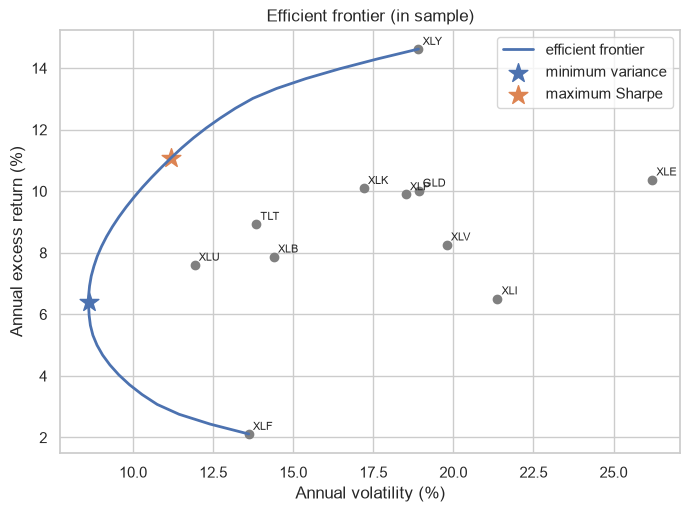

Max Sharpe weights: {'XLK': 0.339, 'XLF': 0.017, 'XLY': 0.364, 'XLU': 0.073, 'XLB': 0.091, 'TLT': 0.116}


In [4]:
mu, cov = exceso.mean().values * 12, exceso.cov().values * 12
frontera = []
for objetivo in np.linspace(mu.min(), mu.max(), 40):
    res = minimize(lambda w: w @ cov @ w, np.ones(len(mu)) / len(mu), bounds=[(0, 1)] * len(mu),
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}, {"type": "eq", "fun": lambda w: w @ mu - objetivo}])
    if res.success:
        frontera.append([np.sqrt(res.x @ cov @ res.x), res.x @ mu])
frontera = np.array(frontera)
w_mv, w_ms = min_var(cov), max_sharpe(mu, cov)

plt.figure(figsize=(8, 5.5))
plt.plot(frontera[:, 0] * 100, frontera[:, 1] * 100, lw=2, label="efficient frontier")
plt.scatter(np.sqrt(np.diag(cov)) * 100, mu * 100, color="grey")
for t, x, y in zip(tickers, np.sqrt(np.diag(cov)), mu):
    plt.annotate(t, (x * 100, y * 100), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.scatter(np.sqrt(w_mv @ cov @ w_mv) * 100, w_mv @ mu * 100, marker="*", s=200, label="minimum variance")
plt.scatter(np.sqrt(w_ms @ cov @ w_ms) * 100, w_ms @ mu * 100, marker="*", s=200, label="maximum Sharpe")
plt.title("Efficient frontier (in sample)")
plt.xlabel("Annual volatility (%)")
plt.ylabel("Annual excess return (%)")
plt.legend()
plt.savefig("figures/efficient_frontier.png", bbox_inches="tight")
plt.show()
print("Max Sharpe weights:", {t: round(float(w), 3) for t, w in zip(tickers, w_ms) if w > 0.005})

## Part 4. Backtest out of sample

Every month we estimate with the last 60 months and we invest with those weights in the next month. We compare 4 strategies: 1/N, minimum variance, maximum Sharpe and inverse volatility (a simple risk parity).

In [5]:
ventana = 60
fechas = ret.index[ventana:]
estrategias = {"1/N": [], "Min variance": [], "Max Sharpe": [], "Inverse vol": []}
pesos_ms = []
for i, f in enumerate(fechas):
    w_ = exceso.iloc[i:i + ventana]
    m, c = w_.mean().values * 12, w_.cov().values * 12
    pesos = {"1/N": np.ones(len(tickers)) / len(tickers), "Min variance": min_var(c), "Max Sharpe": max_sharpe(m, c)}
    iv = 1 / np.sqrt(np.diag(c))
    pesos["Inverse vol"] = iv / iv.sum()
    for k, w in pesos.items():
        estrategias[k].append(w @ ret.loc[f].values)
    pesos_ms.append(pesos["Max Sharpe"])
bt = pd.DataFrame(estrategias, index=fechas)
bt["SPY"] = spy.loc[fechas]
pesos_ms = pd.DataFrame(pesos_ms, index=fechas, columns=tickers)

In [6]:
def metricas(r, rf):
    riqueza = (1 + r).cumprod()
    ex = r - rf
    return pd.Series({"return %": ((1 + r).prod() ** (12 / len(r)) - 1) * 100, "volatility %": r.std() * np.sqrt(12) * 100,
                      "Sharpe": ex.mean() / ex.std() * np.sqrt(12), "max drawdown %": (riqueza / riqueza.cummax() - 1).min() * 100})

resultado = bt.apply(lambda r: metricas(r, ff.loc[fechas, "RF"])).T
resultado.round(2)

,return %,volatility %,Sharpe,max drawdown %
1/N,11.91,11.63,0.91,-17.67
Min variance,9.39,9.01,0.89,-21.69
Max Sharpe,12.45,11.18,0.99,-26.97
Inverse vol,11.68,10.84,0.95,-17.10
SPY,14.26,14.37,0.91,-23.93


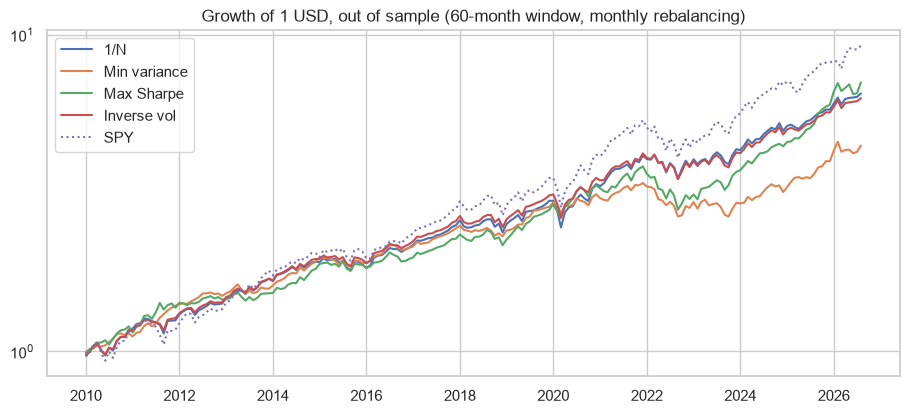

In [7]:
plt.figure(figsize=(11, 4.5))
for c in bt.columns:
    plt.plot(bt.index.to_timestamp(), (1 + bt[c]).cumprod(), label=c, ls=":" if c == "SPY" else "-")
plt.yscale("log")
plt.title("Growth of 1 USD, out of sample (60-month window, monthly rebalancing)")
plt.legend()
plt.savefig("figures/backtest.png", bbox_inches="tight")
plt.show()

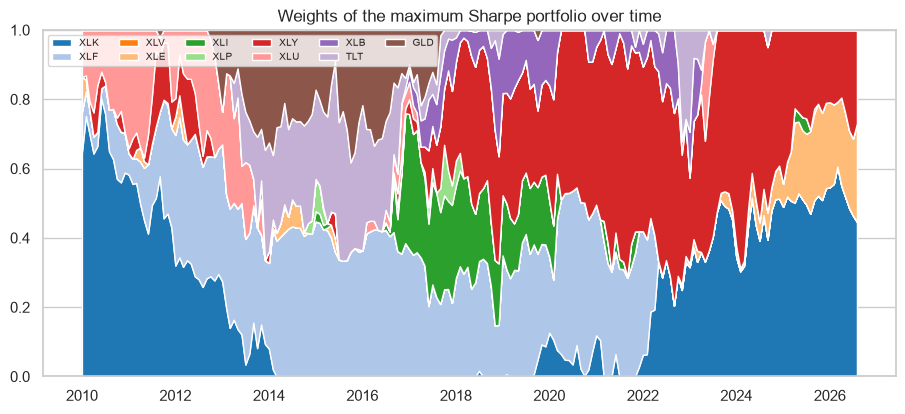

Average monthly turnover of max Sharpe: 0.088


In [8]:
plt.figure(figsize=(11, 4.5))
plt.stackplot(pesos_ms.index.to_timestamp(), pesos_ms.T.values, labels=tickers, colors=plt.cm.tab20.colors[:len(tickers)])
plt.ylim(0, 1)
plt.title("Weights of the maximum Sharpe portfolio over time")
plt.legend(ncol=6, fontsize=7, loc="upper left")
plt.savefig("figures/max_sharpe_weights.png", bbox_inches="tight")
plt.show()
print("Average monthly turnover of max Sharpe:", round(pesos_ms.diff().abs().sum(axis=1).mean() / 2, 3))

The weights of the maximum Sharpe portfolio jump a lot between gold, Treasuries and technology: the expected returns estimated with 5 years of data change all the time, and the optimiser puts everything in the asset that did best recently.

## Part 5. Fama-French + momentum regressions

r - rf = alpha + b1 (Mkt-RF) + b2 SMB + b3 HML + b4 Mom + e, with Newey-West standard errors.

In [9]:
def regresion(y):
    x = sm.add_constant(ff.loc[y.index, ["Mkt-RF", "SMB", "HML", "Mom"]])
    m = sm.OLS(y - ff.loc[y.index, "RF"], x).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return pd.Series({"alpha % year": m.params["const"] * 1200, "t alpha": m.tvalues["const"], "beta mkt": m.params["Mkt-RF"],
                      "SMB": m.params["SMB"], "HML": m.params["HML"], "Mom": m.params["Mom"], "R2": m.rsquared})

pd.DataFrame({t: regresion(ret[t]) for t in tickers}).T.round(2)

,alpha % year,t alpha,beta mkt,SMB,HML,Mom,R2
XLK,2.68,1.79,1.17,-0.17,-0.41,0.04,0.85
XLF,-3.94,-2.07,1.09,-0.15,0.67,-0.19,0.87
XLV,1.81,1.06,0.70,-0.16,0.00,0.03,0.54
XLE,0.97,0.25,0.97,0.13,0.84,0.05,0.49
XLI,-0.60,-0.48,1.06,0.06,0.27,-0.01,0.85
XLP,1.37,0.93,0.60,-0.38,0.14,0.05,0.53
XLY,-0.39,-0.26,1.06,0.19,-0.17,-0.12,0.85
XLU,2.15,0.92,0.53,-0.30,0.11,0.19,0.27
XLB,-2.13,-1.04,1.06,0.02,0.24,-0.07,0.75
TLT,2.34,0.74,-0.04,-0.12,-0.30,0.01,0.08


In [10]:
pd.DataFrame({k: regresion(bt[k]) for k in ["1/N", "Min variance", "Max Sharpe", "Inverse vol"]}).T.round(2)

,alpha % year,t alpha,beta mkt,SMB,HML,Mom,R2
1/N,0.90,0.96,0.74,-0.09,0.13,-0.02,0.89
Min variance,3.31,1.43,0.35,-0.16,-0.04,-0.03,0.32
Max Sharpe,3.89,1.59,0.52,-0.19,-0.23,-0.00,0.49
Inverse vol,1.22,1.17,0.69,-0.12,0.08,-0.00,0.85


## Conclusions

- Out of sample, maximum Sharpe has a slightly better Sharpe ratio than 1/N, but with the deepest drawdown and very unstable weights. Inverse volatility gives almost the same result as max Sharpe with less drawdown and without estimating expected returns, which are the most difficult input.
- Minimum variance and maximum Sharpe have a low market beta (0.35 and 0.52) because they invest a lot in gold and Treasuries. Their alpha against the Fama-French factors is around 3-4% per year but it is not significant (t below 2).
- Gold is the only asset with a significant alpha against the equity factors, and financials (XLF) have a negative alpha and a big exposure to value (HML).